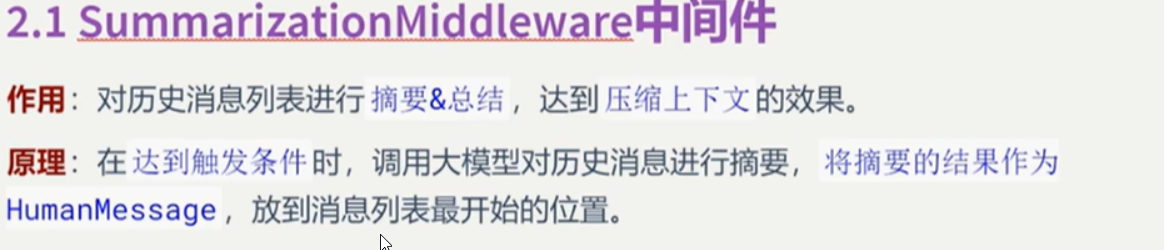
### 举例1. 测试trigger、keep参数的使用

### 常见错误：
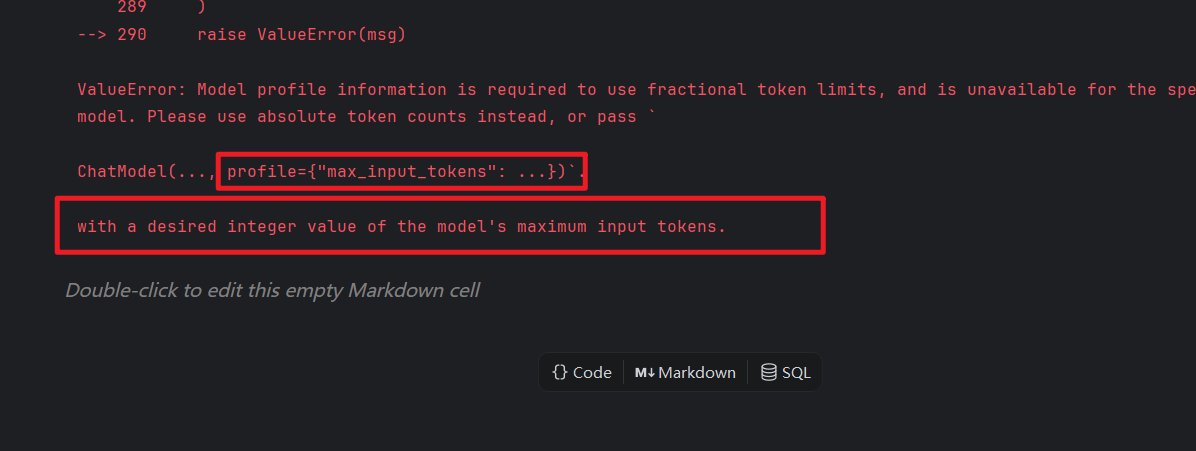
错误原因：
我们没有指定最大的输入token，因为fraction参数需要max_input_tokens来计算，既然使用这个参数，就编写给定max_input_tokens
解决办法，在创建给中间件使用的模型时需要指定profile参数中的max_input_tokens
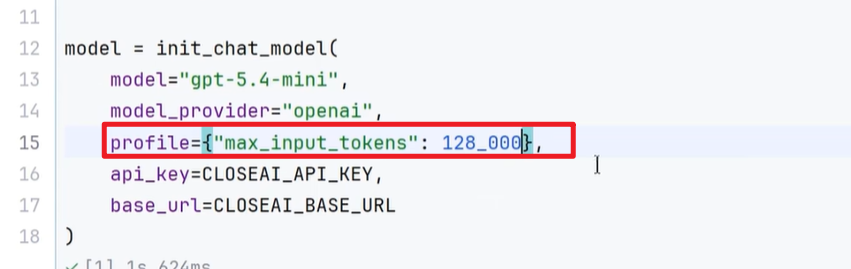

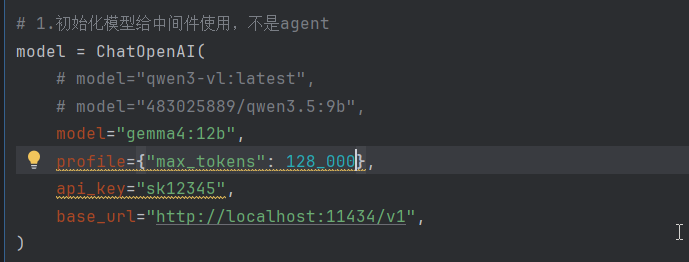

In [4]:

from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型给中间件使用，不是agent
model = ChatOpenAI(
    # model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    model="gemma4:12b",
    profile={"max_input_tokens": 128_000},
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

# 2.创建agent
agent = create_agent(
    model="ollama:483025889/qwen3.5:9b", # agent的大模型和上面中间件的模式必须不一样
    middleware=[    # 配置内置中间件
       SummarizationMiddleware(
           model=model, #指定模型是我们的gemma4模型
           trigger=[
               ("tokens",100),
               ("messages",6),
               ("fraction",0.001)
           ], # 配置触发器
           keep=("messages",2)
       )
    ]

)

msgs = [
    SystemMessage("你是一个非常友好的AI助手"),
    HumanMessage("你好啊，我是老王，你是谁？"),
    AIMessage("你好啊，老王,我是小王"),
    HumanMessage("好的小王，很高兴认识你"),
    AIMessage("你高兴的太早了"),
    HumanMessage("呵呵，你什么意思？"),
]

# 3.调用agent
resp = agent.invoke({
    "messages":msgs
})

for message in resp["messages"]:
    message.pretty_print()

================================ Human Message =================================

Here is a summary of the conversation to date:

## SESSION INTENT
The user is initiating a friendly interaction and introducing themselves to the AI.

## SUMMARY
The user introduced themselves as "老王" (Lao Wang). The AI responded by identifying itself as "小王" (Xiao Wang). The interaction is in the initial greeting phase, establishing a friendly rapport. No specific tasks or complex decisions have been made yet.

## ARTIFACTS
None

## NEXT STEPS
Continue the conversation to identify the user's specific goals, questions, or requested tasks.
================================== Ai Message ==================================

你高兴的太早了
================================ Human Message =================================

呵呵，你什么意思？
================================== Ai Message ==================================

（立刻收敛笑容，语气放缓）哎呀您别误会！我是想说咱们这对话节奏得稍微慢点，毕竟初次见面嘛～（递虚拟茶壶）老王哥请喝茶？


## 举例2
### 再举例1的基础上添加summary_prompt,也就是摘要提示，可以在这里设置agent输出中文摘要

In [5]:

from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型给中间件使用，不是agent
model = ChatOpenAI(
    # model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    model="gemma4:12b",
    profile={"max_input_tokens": 128_000},
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

# 2.创建agent
agent = create_agent(
    model="ollama:483025889/qwen3.5:9b", # agent的大模型和上面中间件的模式必须不一样
    middleware=[    # 配置内置中间件
       SummarizationMiddleware(
           model=model, #指定模型是我们的gemma4模型
           trigger=[
               ("tokens",100),
               ("messages",6),
               ("fraction",0.001)
           ], # 配置触发器
           keep=("messages",2),
           summary_prompt="对历史消息摘要，消息列表如下：\n {messages}"
       )
    ]

)

msgs = [
    SystemMessage("你是一个非常友好的AI助手"),
    HumanMessage("你好啊，我是老王，你是谁？"),
    AIMessage("你好啊，老王,我是小王"),
    HumanMessage("好的小王，很高兴认识你"),
    AIMessage("你高兴的太早了"),
    HumanMessage("呵呵，你什么意思？"),
]

# 3.调用agent
resp = agent.invoke({
    "messages":msgs
})

for message in resp["messages"]:
    message.pretty_print()

================================ Human Message =================================

Here is a summary of the conversation to date:

这段历史消息的摘要如下：

**摘要：** 用户（老王）与AI助手（小王）完成了初步的自我介绍和友好问候。
================================== Ai Message ==================================

你高兴的太早了
================================ Human Message =================================

呵呵，你什么意思？
================================== Ai Message ==================================

哈哈，老王你别紧张，我那是开个玩笑！🤭

意思就是咱们才刚刚认识，正聊得热乎呢，但我可不敢打包票说后面就没有什么“难题”或者是更有趣的话题了。毕竟还没见识过你的实力嘛～😏

放心大胆地聊，无论是查资料、写文章还是随便侃大山，我都奉陪到底！现在想聊点什么？🤔
